Train input: torch.Size([90, 256])
Test input:  torch.Size([600, 256])

[Optimizer comparison]
SGD      | train acc=1.000 | test acc=0.768 | ||W||=4.316
Momentum | train acc=1.000 | test acc=0.782 | ||W||=8.039
Adam     | train acc=1.000 | test acc=0.773 | ||W||=7.182

[L2 regularization comparison]
No L2      | train acc=1.000 | test acc=0.773 | ||W||=7.182
L2 = 0.01  | train acc=1.000 | test acc=0.770 | ||W||=4.187


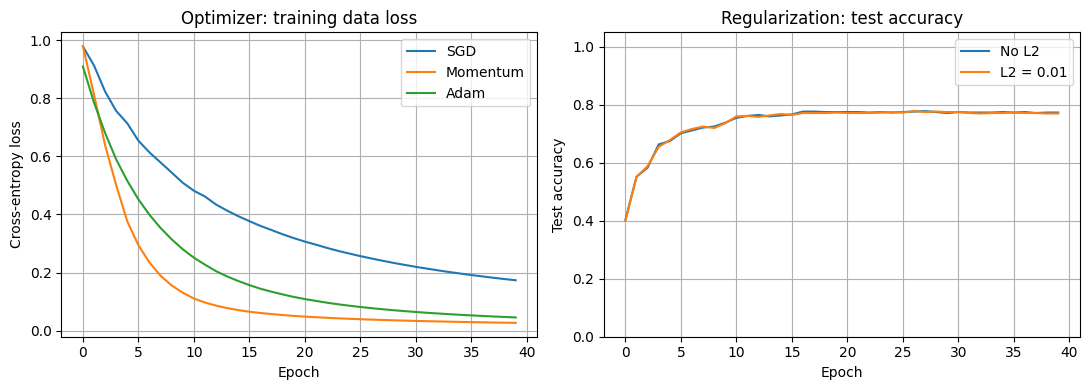

In [1]:
### CS231n_Lec03_review_Normalization_and_Optimization

import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(7)

IMAGE_SIZE = 16
NUM_CLASSES = 3
CLASS_NAMES = ("vertical", "horizontal", "diagonal")


## 1. Generation of synthetic image data with meaningful labels
def make_dataset(num_samples, noise_std=0.35):
    images = torch.zeros(
        num_samples, 1, IMAGE_SIZE, IMAGE_SIZE
    )

    # Generate a random labels array in the range [0, NUM_CLASSES - 1]
    # for a total of num_samples entries
    labels = torch.randint(
        0, NUM_CLASSES, (num_samples,)
    )

    for i in range(num_samples):

        # Select the i-th element from an array of random labels
        label = labels[i].item()

        # Generate a random pixel displacement value between -4 and 4.
        shift = torch.randint(-4, 5, ()).item()

        # vertical image drawing
        if label == 0:
            column = IMAGE_SIZE // 2 + shift
            images[i, 0, :, column] = 1.0

        # horizontal image
        elif label == 1:
            row = IMAGE_SIZE // 2 + shift
            images[i, 0, row, :] = 1.0

        # diagonal image
        else:
            for row in range(IMAGE_SIZE):
                column = row + shift

                if 0 <= column < IMAGE_SIZE:
                    images[i, 0, row, column] = 1.0

        # Add noise to the image
        images[i] += noise_std * torch.randn_like(images[i])
        images[i].clamp_(0.0, 1.0)

    # (N, 1, 16, 16) → (N, 256)
    return images.flatten(start_dim=1), labels


# Create a smaller amount of training data and
# a relatively larger amount of test data.
train_x, train_y = make_dataset(90)
test_x, test_y = make_dataset(600)

print("Train input:", train_x.shape)
print("Test input: ", test_x.shape)



## 2. A function that trains a model using the same initial values
def train_model(
    optimizer_name,
    learning_rate,# Step size for weight updates
    reg_strength=0.0, # Regularization Strength
    epochs=40
):
    # Each experiment begins with the same initial weights.
    torch.manual_seed(0)

    # train_model using Vanilla Linear Classifier
    model = nn.Linear(
        IMAGE_SIZE * IMAGE_SIZE,
        NUM_CLASSES
    )

    # Configure the optimizer based on the input variables.
    if optimizer_name == "SGD":
        optimizer = torch.optim.SGD(
            model.parameters(),
            lr=learning_rate
        )

    elif optimizer_name == "Momentum":
        optimizer = torch.optim.SGD(
            model.parameters(),
            lr=learning_rate,
      # Retain 90% of past velocity to smooth out updates and speed up training
            momentum=0.9
        )

    elif optimizer_name == "Adam":
        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=learning_rate
        )

    else:
        raise ValueError("Unknown optimizer")

    # The same sequence of mini-batches is used for each experiment.
    generator = torch.Generator().manual_seed(10)

    # DataLoader from pytorch.utils.data
    # manages batching and shuffling
    loader = DataLoader(
        TensorDataset(train_x, train_y),
        batch_size=30,
        shuffle=True,
        generator=generator
    )

    loss_history = []
    test_accuracy_history = []

    # Perform epoch training for a specified number of times
    for epoch in range(epochs):
        model.train()

        for batch_x, batch_y in loader:

            # predict labels and calculate value of loss
            scores = model(batch_x)
            data_loss = nn.functional.cross_entropy(
                scores, batch_y
            )

            # Apply L2 regularization only to W, excluding the bias b
            l2_loss = (
                reg_strength
                * model.weight.pow(2).sum()
            )

            total_loss = data_loss + l2_loss

            optimizer.zero_grad()
            total_loss.backward()
            optimizer.step()

        # Evaluate on the entire dataset after each epoch - evaluation mode
        model.eval()

        with torch.no_grad():
            train_scores = model(train_x)
            test_scores = model(test_x)

            measured_loss = nn.functional.cross_entropy(
                train_scores, train_y
            )

            test_accuracy = (
                test_scores.argmax(dim=1) == test_y
            ).float().mean()
            # test_scores.argmax(dim=1) is to
            # extract the label index with the highest probability

        loss_history.append(measured_loss.item())
        test_accuracy_history.append(
            test_accuracy.item()
        )

    with torch.no_grad():
        train_accuracy = (
            model(train_x).argmax(dim=1) == train_y
        ).float().mean().item()

        test_accuracy = (
            model(test_x).argmax(dim=1) == test_y
        ).float().mean().item()

        weight_norm = model.weight.norm().item()

    # the output of train_model
    return {
        "model": model,
        "loss": loss_history,
        "test_accuracy_history": test_accuracy_history,
        "train_accuracy": train_accuracy,
        "test_accuracy": test_accuracy,
        "weight_norm": weight_norm,
    } # end of def train_model



## 3. Experiment A: Comparison of Optimizers
optimizer_settings = {
    "SGD": 0.20,
    "Momentum": 0.10,
    "Adam": 0.01,
}

optimizer_results = {}

for name, lr in optimizer_settings.items():
    optimizer_results[name] = train_model(
        optimizer_name=name,
        learning_rate=lr,
        reg_strength=0.0
    )



## 4. Experiment B: Comparison of L2 Regularization
regularization_results = {
    "No L2": train_model(
        "Adam",
        learning_rate=0.01,
        reg_strength=0.0
    ),
    "L2 = 0.01": train_model(
        "Adam",
        learning_rate=0.01,
        reg_strength=0.01
    ),
}



## 5. Numerical Output(train-test accuracy & weight norm)
print("\n[Optimizer comparison]")

for name, result in optimizer_results.items():
    # remind: train_accuracy, test_accuracy, and weight_norm are
    # the part of outputs of def train_model
    print(
        f"{name:8s} | "
        f"train acc={result['train_accuracy']:.3f} | "
        f"test acc={result['test_accuracy']:.3f} | "
        f"||W||={result['weight_norm']:.3f}"
    )

print("\n[L2 regularization comparison]")

# print and compare the model with L2 and without L2 Regulation
for name, result in regularization_results.items():
    print(
        f"{name:10s} | "
        f"train acc={result['train_accuracy']:.3f} | "
        f"test acc={result['test_accuracy']:.3f} | "
        f"||W||={result['weight_norm']:.3f}"
    )



## 6. Visualization of the Learning Process
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for name, result in optimizer_results.items():
    axes[0].plot(
        result["loss"],
        label=name
    )

# the graph to visualize loss decreasing with each optimzer
axes[0].set_title("Optimizer: training data loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].grid(True)
axes[0].legend()

for name, result in regularization_results.items():
    axes[1].plot(
        result["test_accuracy_history"],
        label=name
    )

# the graph to visualize loss decreasing with or without L2 Regulation
axes[1].set_title("Regularization: test accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Test accuracy")
axes[1].set_ylim(0.0, 1.05)
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()